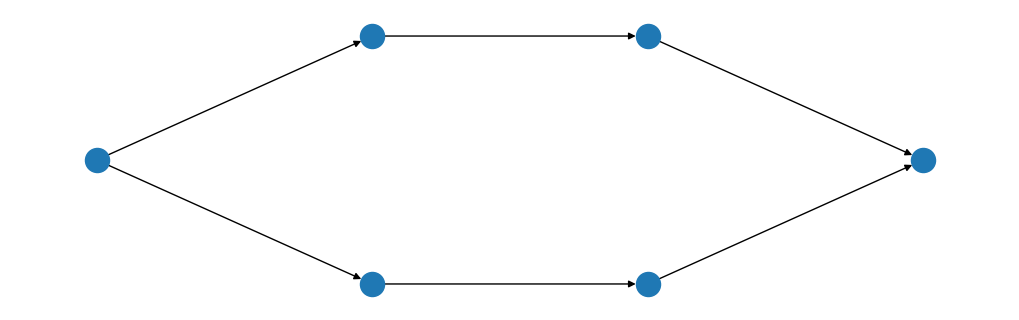

In [6]:
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
import matplotlib.pyplot as plt
edges = [(0,1), (1,3), (3,5), (0,2), (2,4), (4,5)]
pos = {0: (0,1), 1: (1,2), 2: (1, 0), 3: (2,2), 4:(2,0), 5:(3,1)}
G = nx.DiGraph()
G.add_edges_from(edges)
plt.figure(figsize=(10, 3))
nx.draw(G, pos=pos)
plt.show()


# Only Marginal:

In [7]:
def generate_daily_activity(n_days=90, seed=123):
    """Generate synthetic daily activity fractions for nodes 1–4."""
    rng = np.random.default_rng(seed)
    # Average activity levels used to generate the synthetic data.
    baseline = np.array([0.80, 0.70, 0.90, 0.60])
    # Shared environmental variation across days.
    shared_effect = rng.normal(0, 0.6, size=n_days)
    # Node-specific variation across days.
    individual_effect = rng.normal(0, 0.35, size=(n_days, 4))
    # Convert baseline probabilities to logit scale.
    baseline_logits = np.log(baseline / (1 - baseline))
    logits = (baseline_logits[None, :] + 0.45 * shared_effect[:, None] + individual_effect)
    # Convert back to values between 0 and 1.
    activity = 1 / (1 + np.exp(-logits))
    return pd.DataFrame(activity, index=pd.RangeIndex(1, n_days + 1, name="day"), columns=[1, 2, 3, 4],)


activity_df = generate_daily_activity(n_days=90)
print(activity_df.head())
print("Average activity by node:")
print(activity_df.mean())

            1         2         3         4
day                                        
1    0.825106  0.653180  0.890763  0.521571
2    0.851634  0.579367  0.879919  0.473867
3    0.883215  0.816476  0.914076  0.791426
4    0.791605  0.602403  0.895779  0.641952
5    0.825306  0.868606  0.939634  0.779005
Average activity by node:
1    0.797589
2    0.686556
3    0.894307
4    0.611327
dtype: float64


In [8]:
def simulate_connectivity(activity_df, n_samples_per_day=2000, rho=0.0, seed=456,):
    """
    Simulate network connectivity using daily activity fractions.
    rho controls the dependence between node states:
    (0.0, 0.4, 0.8) = (independence, moderate positive dependence, strong positive dependence)
    daily_results: Estimated path and network connectivity probabilities by day.
    samples_df : Simulated node states and connectivity outcomes.
    """
    rng = np.random.default_rng(seed)
    node_ids = list(activity_df.columns)
    n_nodes = len(node_ids)
    if not (-1 / 3 < rho < 1):
        raise ValueError("For this equicorrelation model, use -1/3 < rho < 1.")

    # Correlation matrix for the latent normal variables.
    corr = np.full((n_nodes, n_nodes), rho)
    np.fill_diagonal(corr, 1.0)
    daily_records, sample_records = [], []
    for day, row in activity_df.iterrows():
        # Marginal activity probabilities for this day.
        p = np.clip(row.to_numpy(dtype=float), 1e-8, 1 - 1e-8)
        # Generate correlated latent normal variables.
        latent = rng.multivariate_normal(mean=np.zeros(n_nodes), cov=corr, size=n_samples_per_day,)
        # Convert marginal probabilities to thresholds.
        thresholds = norm.ppf(p)
        # Generate binary operational states.
        states = (latent <= thresholds[None, :]).astype(np.int8)
        # Extract the four node states.
        x1 = states[:, 0]
        x2 = states[:, 1]
        x3 = states[:, 2]
        x4 = states[:, 3]
        # Evaluate the two paths.
        path_1 = x1 * x3
        path_2 = x2 * x4
        # Network connected if either path works.
        connected = ((path_1 + path_2) > 0).astype(np.int8)
        # Save daily estimates.
        daily_records.append({
            "day": day,
            "rho": rho,
            "node_1_activity": x1.mean(),
            "node_2_activity": x2.mean(),
            "node_3_activity": x3.mean(),
            "node_4_activity": x4.mean(),
            "path_1_probability": path_1.mean(),
            "path_2_probability": path_2.mean(),
            "both_paths_probability": (path_1 * path_2).mean(),
            "connectivity_probability": connected.mean(),
        })
        # Save the simulated configurations.
        day_samples = pd.DataFrame(states, columns=node_ids)
        day_samples["day"] = day
        day_samples["path_1"] = path_1
        day_samples["path_2"] = path_2
        day_samples["connected"] = connected
        sample_records.append(day_samples)
    daily_results = pd.DataFrame(daily_records).set_index("day")
    samples_df = pd.concat(sample_records, ignore_index=True)
    return daily_results, samples_df

In [9]:
independent_daily, independent_samples = simulate_connectivity(activity_df, rho=0.0, seed=456,)
moderate_daily, moderate_samples = simulate_connectivity(activity_df, rho=0.4, seed=456,)
strong_daily, strong_samples = simulate_connectivity(activity_df, rho=0.8, seed=456,)
comparison = pd.DataFrame({
    "independent": independent_daily["connectivity_probability"], 
    "moderate_dependence": moderate_daily["connectivity_probability"], 
    "strong_dependence": strong_daily["connectivity_probability"],
    })
print(comparison.mean().round(4))

independent            0.8337
moderate_dependence    0.7985
strong_dependence      0.7867
dtype: float64


In [10]:
marginal_comparison = pd.DataFrame({
    "observed_node_1": activity_df[1],
    "simulated_node_1": strong_daily["node_1_activity"],
    "observed_node_3": activity_df[3],
    "simulated_node_3": strong_daily["node_3_activity"],
})

print(marginal_comparison.head())

     observed_node_1  simulated_node_1  observed_node_3  simulated_node_3
day                                                                      
1           0.825106            0.8265         0.890763            0.8910
2           0.851634            0.8420         0.879919            0.8755
3           0.883215            0.8910         0.914076            0.9095
4           0.791605            0.7710         0.895779            0.8945
5           0.825306            0.8220         0.939634            0.9365


In [12]:
from scipy.optimize import minimize_scalar


def estimate_gaussian_copula_rho(observed_states, node_ids=(1, 2, 3, 4), n_sim=100_000, seed=123,):
    """
    Estimate a common latent Gaussian-copula rho by matching
    simulated and observed pairwise binary correlations.
    Assumes synchronized observations and a common latent rho.
    """
    X = observed_states[list(node_ids)].to_numpy(dtype=float)
    if not np.isin(X, [0, 1]).all():
        raise ValueError("Observed states must contain only 0 and 1.")
    p = X.mean(axis=0)
    if np.any((p <= 0) | (p >= 1)):
        raise ValueError("Every node must have both active and inactive observations.")
    target_corr = np.corrcoef(X, rowvar=False)
    thresholds = norm.ppf(p)
    # Use common random numbers to make calibration more stable.
    rng = np.random.default_rng(seed)
    Z = rng.standard_normal((n_sim, len(node_ids)))
    def objective(rho):
        R = np.full((len(node_ids), len(node_ids)), rho)
        np.fill_diagonal(R, 1.0)
        # Transform independent standard normals to correlated normals.
        L = np.linalg.cholesky(R)
        latent = Z @ L.T
        simulated = (latent <= thresholds).astype(int)
        simulated_corr = np.corrcoef(simulated, rowvar=False)
        upper = np.triu_indices(len(node_ids), k=1)
        return np.mean((simulated_corr[upper] - target_corr[upper]) ** 2)

    result = minimize_scalar(objective, bounds=(-1 / (len(node_ids) - 1) + 1e-5, 0.999), method="bounded", options={"xatol": 1e-4},)
    return {"rho": result.x, "objective": result.fun, "observed_correlations": target_corr, "marginal_activity": dict(zip(node_ids, p)),}

# Joint Data:

In [15]:
def generate_observed_states(n_observations=10_000, activity_probabilities=(0.80, 0.70, 0.90, 0.60), rho=0.0, seed=123,):
    """
    Generate synchronized binary observations for nodes 1, 2, 3, and 4.
    """
    p = np.asarray(activity_probabilities, dtype=float)
    n_nodes = len(p)
    if n_nodes != 4:
        raise ValueError("Expected four node activity probabilities.")
    if np.any((p <= 0) | (p >= 1)):
        raise ValueError("Activity probabilities must be strictly between 0 and 1.")
    if not (-1 / 3 < rho < 1):
        raise ValueError("For four nodes with equicorrelation, require -1/3 < rho < 1.")
    if n_observations < 1:
        raise ValueError("n_observations must be positive.")
    rng = np.random.default_rng(seed)
    # Equicorrelation matrix for the latent Gaussian variables.
    correlation = np.full((n_nodes, n_nodes), rho)
    np.fill_diagonal(correlation, 1.0)
    # Generate correlated latent Gaussian observations.
    latent = rng.multivariate_normal(mean=np.zeros(n_nodes), cov=correlation, size=n_observations,)
    # Threshold each node to achieve its specified marginal probability.
    thresholds = norm.ppf(p)
    states = (latent <= thresholds).astype(np.int8)
    return pd.DataFrame(states, columns=[1, 2, 3, 4], index=pd.RangeIndex(n_observations, name="observation"),)

In [18]:
observed_independent = generate_observed_states(n_observations=10_000, rho=0.0, seed=123,)
observed_dependent = generate_observed_states(n_observations=10_000, rho=0.7, seed=123,)

# Check the observed marginal activity rates.
print(observed_dependent.mean().round(3))

# Check the observed binary-state correlations.
print(observed_dependent.corr().round(3))
observed_states = observed_dependent

1    0.798
2    0.696
3    0.901
4    0.599
dtype: float64
       1      2      3      4
1  1.000  0.460  0.396  0.436
2  0.460  1.000  0.375  0.481
3  0.396  0.375  1.000  0.343
4  0.436  0.481  0.343  1.000


In [19]:
def analyze_joint_data(observed_states):
    X = observed_states[[1, 2, 3, 4]].astype(int)

    results = pd.Series({
        "p1": X[1].mean(),
        "p2": X[2].mean(),
        "p3": X[3].mean(),
        "p4": X[4].mean(),
        "path_1_probability": (X[1] & X[3]).mean(),
        "path_2_probability": (X[2] & X[4]).mean(),
        "both_paths_probability": (
            X[1] & X[2] & X[3] & X[4]
        ).mean(),
        "connectivity_probability": (
            (X[1] & X[3]) | (X[2] & X[4])
        ).mean(),
    })

    return results

observed_results = analyze_joint_data(observed_states)
print(observed_results.round(4))

p1                          0.7982
p2                          0.6960
p3                          0.9006
p4                          0.5991
path_1_probability          0.7664
path_2_probability          0.5253
both_paths_probability      0.5030
connectivity_probability    0.7887
dtype: float64


In [20]:
p = observed_states[[1, 2, 3, 4]].mean()

independent_estimate = (1 - (1 - p[1] * p[3]) * (1 - p[2] * p[4]))

empirical_estimate = observed_results["connectivity_probability"]

print(f"Empirical connectivity:    {empirical_estimate:.4f}")
print(f"Independence approximation: {independent_estimate:.4f}")
print(f"Difference:                {empirical_estimate - independent_estimate:.4f}")

fit = estimate_gaussian_copula_rho(observed_states)

rho_hat = fit["rho"]

print(f"Estimated latent rho: {rho_hat:.4f}")
print(f"Pairwise correlation fit error: {fit['objective']:.6f}")

Empirical connectivity:    0.7887
Independence approximation: 0.8361
Difference:                -0.0474
Estimated latent rho: 0.7031
Pairwise correlation fit error: 0.000024


In [21]:
# Estimate marginal probabilities from the joint observations.
p_hat = observed_states[[1, 2, 3, 4]].mean()

# One set of marginal probabilities for the fitted model.
marginals = pd.DataFrame([p_hat.to_numpy()], index=["observed_marginals"], columns=[1, 2, 3, 4],)

# Simulate the fitted dependence model.
fitted_daily, fitted_samples = simulate_connectivity(marginals, n_samples_per_day=200_000, rho=rho_hat, seed=789,)

observed_connectivity = observed_results["connectivity_probability"]
predicted_connectivity = fitted_daily.loc[
    "observed_marginals", "connectivity_probability"
]

print(f"Observed connectivity:  {observed_connectivity:.4f}")
print(f"Fitted-model estimate:  {predicted_connectivity:.4f}")
print(f"Difference:             {predicted_connectivity - observed_connectivity:.4f}")

Observed connectivity:  0.7887
Fitted-model estimate:  0.7903
Difference:             0.0016


# Markov Model:

In [22]:
import numpy as np
import pandas as pd


def simulate_node_states(n_nodes=4, total_time=1000.0, mean_active_time=80.0, mean_inactive_time=20.0, time_step=1.0, seed=123,):
    """
    Simulate active/inactive states over time for multiple nodes.

    State:
        1 = active
        0 = inactive

    Active and inactive durations are exponentially distributed.
    Nodes transition independently in this version.

    Returns
    -------
    pandas.DataFrame
        Rows are time points; columns are node IDs (1, ..., n_nodes).
    """
    if n_nodes < 1 or total_time <= 0 or time_step <= 0:
        raise ValueError("n_nodes, total_time, and time_step must be positive.")

    if mean_active_time <= 0 or mean_inactive_time <= 0:
        raise ValueError("Mean durations must be positive.")

    rng = np.random.default_rng(seed)
    times = np.arange(0, total_time, time_step)
    states = np.zeros((len(times), n_nodes), dtype=np.int8)

    for j in range(n_nodes):
        t = 0.0
        active = bool(rng.integers(0, 2))

        while t < total_time:
            mean_duration = (mean_active_time if active else mean_inactive_time)
            duration = rng.exponential(mean_duration)
            end_time = min(t + duration, total_time)

            start_idx = np.searchsorted(times, t, side="left")
            end_idx = np.searchsorted(times, end_time, side="left")
            states[start_idx:end_idx, j] = int(active)

            t = end_time
            active = not active

    return pd.DataFrame(states, index=pd.Index(times, name="time"), columns=range(1, n_nodes + 1),)

In [23]:
observed_states = simulate_node_states(n_nodes=4, total_time=1000, mean_active_time=80, mean_inactive_time=20, time_step=1, seed=123,)
print(observed_states.head(20))

      1  2  3  4
time            
0     0  1  1  0
1     0  1  1  0
2     0  1  1  0
3     1  1  1  0
4     1  1  1  0
5     1  1  1  0
6     1  1  1  0
7     1  1  1  0
8     1  1  1  0
9     1  1  1  0
10    1  1  1  0
11    1  1  1  0
12    1  1  1  0
13    1  1  1  0
14    1  1  1  0
15    1  1  1  0
16    1  1  1  0
17    1  1  1  0
18    1  1  1  0
19    1  1  1  1


In [24]:
activity_percentages = 100 * observed_states.mean()
print(activity_percentages.round(2))

path_1 = observed_states[1] & observed_states[3]
path_2 = observed_states[2] & observed_states[4]

connected = path_1 | path_2

print(f"Path 1 availability: {100 * path_1.mean():.2f}%")
print(f"Path 2 availability: {100 * path_2.mean():.2f}%")
print(f"Network connectivity: {100 * connected.mean():.2f}%")

1    87.4
2    80.0
3    76.8
4    74.0
dtype: float64
Path 1 availability: 66.40%
Path 2 availability: 60.80%
Network connectivity: 89.00%


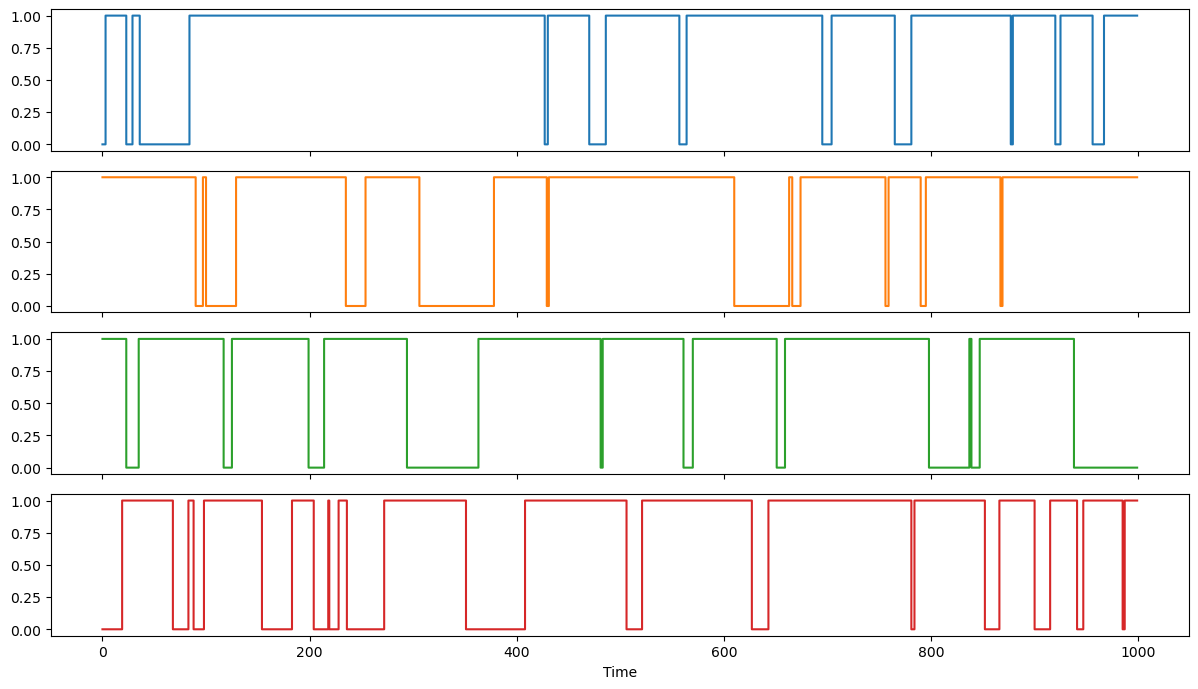

In [25]:
import matplotlib.pyplot as plt

observed_states.plot(drawstyle="steps-post", subplots=True, layout=(4, 1), figsize=(12, 7), sharex=True, legend=False,)

plt.xlabel("Time")
plt.tight_layout()
plt.show()

In [26]:
import numpy as np
import pandas as pd


def simulate_delayed_node_states(
    n_nodes=4,
    total_time=1000.0,
    time_step=1.0,
    mean_active_time=80.0,
    mean_inactive_time=20.0,
    median_latency=5.0,
    latency_sigma=0.5,
    initial_state=None,
    reporting_policy="deliver_all",
    seed=123,
):
    """
    Simulate true node states and delayed reported states.

    States:
        1 = active
        0 = inactive

    True state transitions follow a two-state continuous-time
    Markov model, observed on a discrete time grid.

    Reporting latency is lognormal with the specified median
    and log-scale standard deviation.

    reporting_policy:
        "deliver_all":
            Every report is delivered, even if it is stale.
            An older report can overwrite a newer state.

        "latest_only":
            Ignore a report if a newer state change has already
            occurred before that report arrives.

    Returns
    -------
    true_states : DataFrame
        Actual physical states over time.
    reported_states : DataFrame
        States visible to the monitoring system over time.
    events : DataFrame
        True state changes and their scheduled report times.
    """
    if n_nodes < 1 or total_time <= 0 or time_step <= 0:
        raise ValueError("n_nodes, total_time, and time_step must be positive.")

    if mean_active_time <= 0 or mean_inactive_time <= 0:
        raise ValueError("Mean active and inactive times must be positive.")

    if median_latency < 0 or latency_sigma < 0:
        raise ValueError("Latency parameters must be nonnegative.")

    if reporting_policy not in {"deliver_all", "latest_only"}:
        raise ValueError(
            "reporting_policy must be 'deliver_all' or 'latest_only'."
        )

    rng = np.random.default_rng(seed)
    times = np.arange(0, total_time + time_step * 0.5, time_step)
    n_times = len(times)
    node_ids = list(range(1, n_nodes + 1))

    # Initialize nodes at stationarity unless initial states are supplied.
    if initial_state is None:
        p_active = mean_active_time / (mean_active_time + mean_inactive_time)
        initial = rng.binomial(1, p_active, size=n_nodes).astype(np.int8)
    else:
        initial = np.asarray(initial_state, dtype=np.int8)
        if initial.shape != (n_nodes,) or not np.isin(initial, [0, 1]).all():
            raise ValueError("initial_state must contain one 0/1 value per node.")

    true = np.zeros((n_times, n_nodes), dtype=np.int8)
    reported = np.zeros_like(true)
    true[0] = initial

    # Each event: (delivery_index, node_index, new_state, change_id, change_time, delivery_time, latency)
    scheduled_events = []
    event_id = 0

    for j in range(n_nodes):
        state = int(initial[j])
        change_id = 0
        for k in range(1, n_times):
            mean_duration = (mean_active_time if state == 1 else mean_inactive_time)
            # Exact transition probability over one grid interval for an exponential holding-time model.
            p_transition = 1 - np.exp(-time_step / mean_duration)
            if rng.random() < p_transition:
                state = 1 - state
                change_id += 1
                change_time = times[k]
                if median_latency == 0:
                    latency = 0.0
                else:
                    latency = rng.lognormal(mean=np.log(median_latency), sigma=latency_sigma,)
                delivery_time = change_time + latency
                delivery_index = int(np.searchsorted(times, delivery_time, side="left"))
                # Only deliveries within the simulation horizon are recorded.
                if delivery_index < n_times:
                    scheduled_events.append((delivery_index, j, state, change_id, change_time, delivery_time, latency, event_id))
                    event_id += 1
            true[k, j] = state

    # Replay reports in scheduled delivery order.
    reported[0] = initial
    scheduled_events.sort(key=lambda e: (e[0], e[7]))
    event_table = []
    event_pointer = 0
    last_change_id = np.zeros(n_nodes, dtype=int)

    # Apply any reports due at each time point.
    for k in range(1, n_times):
        reported[k] = reported[k - 1]

        while (event_pointer < len(scheduled_events) and scheduled_events[event_pointer][0] <= k):
            (delivery_index, j, new_state, change_id, change_time, delivery_time, latency, eid) = scheduled_events[event_pointer]

            delivered = True
            if (reporting_policy == "latest_only" and change_id < last_change_id[j]):
                delivered = False

            if delivered:
                reported[k:, j] = reported[k:, j]
                reported[k, j] = new_state
                last_change_id[j] = max(last_change_id[j], change_id)

            event_table.append({
                "event_id": eid,
                "node": node_ids[j],
                "true_change_time": change_time,
                "new_state": new_state,
                "latency": latency,
                "scheduled_delivery_time": delivery_time,
                "delivery_grid_time": times[delivery_index],
                "delivered": delivered,
            })

            event_pointer += 1

        # Preserve reports from earlier steps for nodes with no new delivery.
        # The next iteration carries forward this row.

    # Reconstruct reported state correctly by replaying all events.
    # This second pass avoids any ambiguity from simultaneous deliveries.
    reported = np.zeros_like(true)
    reported[0] = initial
    last_change_id = np.zeros(n_nodes, dtype=int)
    events_by_time = {}
    for e in scheduled_events:
        events_by_time.setdefault(e[0], []).append(e)

    for k in range(1, n_times):
        reported[k] = reported[k - 1]
        for e in events_by_time.get(k, []):
            _, j, new_state, change_id, *_ = e
            if reporting_policy == "deliver_all" or change_id >= last_change_id[j]:
                reported[k, j] = new_state
                last_change_id[j] = max(last_change_id[j], change_id)

    true_df = pd.DataFrame(true, index=times, columns=node_ids)
    true_df.index.name = "time"

    reported_df = pd.DataFrame(reported, index=times, columns=node_ids)
    reported_df.index.name = "time"

    events_df = pd.DataFrame(event_table)

    return true_df, reported_df, events_df

In [27]:
true_states, reported_states, events = simulate_delayed_node_states(
    n_nodes=4,
    total_time=1000,
    time_step=1,
    mean_active_time=80,
    mean_inactive_time=20,
    median_latency=5,
    latency_sigma=0.5,
    reporting_policy="deliver_all",
    seed=123,
)

# Connectivity of the true physical network.
true_connected = (
    (true_states[1] & true_states[3])
    | (true_states[2] & true_states[4])
)

# Connectivity inferred from the delayed reports.
reported_connected = (
    (reported_states[1] & reported_states[3])
    | (reported_states[2] & reported_states[4])
)

print(f"True connectivity:     {100 * true_connected.mean():.2f}%")
print(f"Reported connectivity: {100 * reported_connected.mean():.2f}%")
print(f"Misclassification rate: {100 * (true_connected != reported_connected).mean():.2f}%")

print(events.head())

True connectivity:     77.42%
Reported connectivity: 80.12%
Misclassification rate: 16.48%
   event_id  node  true_change_time  new_state    latency  \
0        65     4              10.0          0   5.388123   
1        66     4              12.0          1   3.583372   
2        67     4              13.0          0  12.921284   
3        68     4              44.0          1   1.251945   
4         0     1              49.0          0   5.140297   

   scheduled_delivery_time  delivery_grid_time  delivered  
0                15.388123                16.0       True  
1                15.583372                16.0       True  
2                25.921284                26.0       True  
3                45.251945                46.0       True  
4                54.140297                55.0       True  


In [28]:
results = []

for latency in [0, 2, 5, 10, 20]:
    true_states, reported_states, events = simulate_delayed_node_states(
        median_latency=latency,
        latency_sigma=0.5,
        seed=123,
    )

    true_conn = (
        (true_states[1] & true_states[3])
        | (true_states[2] & true_states[4])
    )
    reported_conn = (
        (reported_states[1] & reported_states[3])
        | (reported_states[2] & reported_states[4])
    )

    results.append({
        "median_latency": latency,
        "true_connectivity": true_conn.mean(),
        "reported_connectivity": reported_conn.mean(),
        "misclassification_rate": (true_conn != reported_conn).mean(),
    })

latency_results = pd.DataFrame(results)
print(latency_results.round(4))

   median_latency  true_connectivity  reported_connectivity  \
0               0             0.7323                 0.7323   
1               2             0.7742                 0.7622   
2               5             0.7742                 0.8012   
3              10             0.7742                 0.7453   
4              20             0.7742                 0.7323   

   misclassification_rate  
0                  0.0000  
1                  0.0779  
2                  0.1648  
3                  0.2308  
4                  0.2877  


# Strategy:

In [29]:
import itertools
import numpy as np
from scipy.optimize import linprog


def connectivity_bounds(marginals):
    """
    Sharp connectivity bounds for two alternative routes:
        Route 1: 1 -> 3
        Route 2: 2 -> 4

    Assumes only the four marginal activity probabilities are known.
    """
    p = np.asarray(marginals, dtype=float)

    if p.shape != (4,) or np.any((p < 0) | (p > 1)):
        raise ValueError("Provide four marginal probabilities in [0, 1].")

    # Enumerate every possible joint state of the four nodes.
    states = np.array(list(itertools.product([0, 1], repeat=4)), dtype=int,)
    connected = (((states[:, 0] == 1) & (states[:, 2] == 1)) | ((states[:, 1] == 1) & (states[:, 3] == 1))).astype(float)

    # Unknowns are the probabilities assigned to the 16 states.
    A_eq = np.vstack([np.ones(len(states)), states.T])
    b_eq = np.r_[1.0, p]
    variable_bounds = [(0, None)] * len(states)
    minimum = linprog(connected, A_eq=A_eq, b_eq=b_eq, bounds=variable_bounds, method="highs",)
    maximum = linprog(-connected, A_eq=A_eq, b_eq=b_eq, bounds=variable_bounds, method="highs",)

    if not minimum.success or not maximum.success:
        raise RuntimeError("Connectivity-bound optimization failed.")

    return {
        "lower_bound": minimum.fun,
        "upper_bound": -maximum.fun,
        "lower_distribution": minimum.x,
        "upper_distribution": maximum.x,
        "states": states,
    }

In [30]:
p = [0.80, 0.70, 0.90, 0.60]

bounds = connectivity_bounds(p)

independent = 1 - (1 - p[0] * p[2]) * (1 - p[1] * p[3])

print(f"Minimum possible connectivity: {bounds['lower_bound']:.4f}")
print(f"Independence estimate:          {independent:.4f}")
print(f"Maximum possible connectivity: {bounds['upper_bound']:.4f}")

Minimum possible connectivity: 0.7000
Independence estimate:          0.8376
Maximum possible connectivity: 1.0000


In [31]:
def connectivity_by_rho(marginals=(0.80, 0.70, 0.90, 0.60), rhos=(0.0, 0.2, 0.4, 0.6, 0.8), n_sim=200_000, seed=123,):
    from scipy.stats import norm

    p = np.asarray(marginals, dtype=float)
    rng = np.random.default_rng(seed)
    results = []

    for rho in rhos:
        if not (-1 / 3 < rho < 1):
            raise ValueError("For four equicorrelated latent variables, rho must be in (-1/3, 1).")

        corr = np.full((4, 4), rho)
        np.fill_diagonal(corr, 1.0)

        z = rng.multivariate_normal(np.zeros(4), corr, size=n_sim)
        x = (z <= norm.ppf(p)).astype(np.int8)

        path1 = (x[:, 0] == 1) & (x[:, 2] == 1)
        path2 = (x[:, 1] == 1) & (x[:, 3] == 1)
        connected = path1 | path2

        results.append({
            "rho": rho,
            "connectivity": connected.mean(),
            "path_1": path1.mean(),
            "path_2": path2.mean(),
            "both_paths": (path1 & path2).mean(),
        })

    return pd.DataFrame(results)

In [32]:
scenario_results = connectivity_by_rho()
print(scenario_results.round(4))

   rho  connectivity  path_1  path_2  both_paths
0  0.0        0.8372  0.7202  0.4182      0.3012
1  0.2        0.8176  0.7317  0.4485      0.3625
2  0.4        0.8039  0.7453  0.4780      0.4194
3  0.6        0.7936  0.7592  0.5086      0.4742
4  0.8        0.7929  0.7803  0.5467      0.5341


In [34]:
import numpy as np
import pandas as pd


def bootstrap_marginals(observed_states, block_length=20, n_bootstrap=2000, seed=123,):
    """
    Bootstrap node activity probabilities from binary time series.
    Each node's series is resampled independently, preserving
    within-node temporal dependence within each sampled block.

    Returns
    -------
    bootstrap_p : DataFrame
        One row per bootstrap replicate and one column per node.
    """
    X = observed_states.to_numpy(dtype=float)

    if X.ndim != 2 or X.shape[0] < 2:
        raise ValueError("Provide at least two observations.")

    if not np.isin(X, [0, 1]).all():
        raise ValueError("States must be binary (0 or 1).")

    T, n_nodes = X.shape

    if not 1 <= block_length <= T:
        raise ValueError("block_length must be between 1 and T.")

    if n_bootstrap < 1:
        raise ValueError("n_bootstrap must be positive.")

    rng = np.random.default_rng(seed)
    bootstrap_p = np.empty((n_bootstrap, n_nodes))

    n_blocks = int(np.ceil(T / block_length))

    for b in range(n_bootstrap):
        for j in range(n_nodes):
            starts = rng.integers(0, T, size=n_blocks)
            indices = np.concatenate([(start + np.arange(block_length)) % T for start in starts])[:T]
            bootstrap_p[b, j] = X[indices, j].mean()

    return pd.DataFrame(bootstrap_p, columns=observed_states.columns,)

In [35]:
bootstrap_p = bootstrap_marginals(observed_states, block_length=20, n_bootstrap=2000, seed=123,)

# Estimated marginal probabilities
p_hat = observed_states.mean()

# 95% bootstrap confidence intervals
marginal_summary = pd.DataFrame({
    "estimate": p_hat,
    "lower_95": bootstrap_p.quantile(0.025),
    "upper_95": bootstrap_p.quantile(0.975),
})

print(marginal_summary.round(4))

   estimate  lower_95  upper_95
1     0.874     0.805     0.933
2     0.800     0.700     0.895
3     0.768     0.672     0.861
4     0.740     0.637     0.832


In [36]:
def bootstrap_independence_connectivity(bootstrap_p):
    p1 = bootstrap_p.iloc[:, 0]
    p2 = bootstrap_p.iloc[:, 1]
    p3 = bootstrap_p.iloc[:, 2]
    p4 = bootstrap_p.iloc[:, 3]

    return 1 - (1 - p1 * p3) * (1 - p2 * p4)


connectivity_boot = bootstrap_independence_connectivity(bootstrap_p)

print("Independence-model connectivity estimate:",
      1 - (1 - p_hat.iloc[0] * p_hat.iloc[2])
        * (1 - p_hat.iloc[1] * p_hat.iloc[3]))

print("95% bootstrap interval:",
      np.quantile(connectivity_boot, [0.025, 0.975]).round(4))

Independence-model connectivity estimate: 0.865862656
95% bootstrap interval: [0.8087 0.9162]


In [37]:
def bootstrap_connectivity_bounds(bootstrap_p):
    records = []

    for _, row in bootstrap_p.iterrows():
        result = connectivity_bounds(row.to_numpy(dtype=float))

        records.append({
            "lower_bound": result["lower_bound"],
            "upper_bound": result["upper_bound"],
        })

    return pd.DataFrame(records)


bounds_boot = bootstrap_connectivity_bounds(bootstrap_p)

print(
    bounds_boot.quantile([0.025, 0.50, 0.975]).round(4)
)

       lower_bound  upper_bound
0.025        0.543          1.0
0.500        0.649          1.0
0.975        0.755          1.0


In [ ]:
import itertools
import numpy as np
import networkx as nx
import pandas as pd
import pgmpy
from pgmpy.causal_discovery import HillClimbSearch
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD

print("pgmpy version:", pgmpy.__version__)
nodes = ["node_1", "node_2", "node_3", "node_4"]

# Ensure the data are recognized as discrete binary variables.
data = df_time[nodes].copy()
for node in nodes:
    data[node] = pd.Categorical(data[node].astype(int), categories=[0, 1],)

# Learn a DAG directly.
hc = HillClimbSearch(scoring_method="bic-d", max_indegree=2, max_iter=1000, return_type="dag", show_progress=False,)
hc.fit(data)
learned_dag = hc.causal_graph_
print("Learned edges:", list(learned_dag.edges()))
print("Is DAG:", nx.is_directed_acyclic_graph(learned_dag))

# Construct the Bayesian network.
model = DiscreteBayesianNetwork()
model.add_nodes_from(nodes)
model.add_edges_from(learned_dag.edges())

# BDeu equivalent sample size
ess = 10
state_names = {node: [0, 1] for node in nodes}
cpds = []
for node in nodes:
    parents = sorted(model.get_parents(node))
    n_parent_configs = 2 ** len(parents)
    # BDeu prior pseudo-count for each cell
    alpha = ess / (2 * n_parent_configs)
    # Rows correspond to node states 0 and 1.
    # Columns correspond to configurations of parent states.
    values = np.zeros((2, n_parent_configs), dtype=float)
    parent_configs = (list(itertools.product([0, 1], repeat=len(parents))) if parents else [()])
    for j, config in enumerate(parent_configs):
        mask = np.ones(len(data), dtype=bool)
        for parent, state in zip(parents, config):
            mask &= data[parent].astype(int).to_numpy() == state
        observed = data.loc[mask, node].astype(int)
        counts = observed.value_counts()
        for state in [0, 1]:
            values[state, j] = counts.get(state, 0) + alpha
        # Normalize the conditional probabilities.
        values[:, j] /= values[:, j].sum()
    cpd = TabularCPD(
        variable=node, 
        variable_card=2, 
        values=values, 
        evidence=parents if parents else None, 
        evidence_card=[2] * len(parents) if parents else None, 
        state_names={parent: [0, 1] for parent in parents} | {node: [0, 1]},
        )
    cpds.append(cpd)
model.add_cpds(*cpds)
print("Model valid:", model.check_model())
for node in nodes:
    print(f"\n{node}")
    print(model.get_cpds(node))

In [ ]:
from other.helper_txt_and_scripts.notebook_txt import ipynb_to_txt, txt_to_ipynb
ipynb_to_txt(r"C:/Users/Drew/Documents/MyFiles/repo/other/2m.ipynb", r"C:/Users/Drew/Documents/MyFiles/repo/other/timeline.txt")


WindowsPath('C:/Users/Drew/Documents/MyFiles/repo/other/timeline.txt')